# Heuers' statistical Football model

The following implementation aims to recreate the Football model of Prof. Dr. Andreas Heuer.

In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
from functools import lru_cache
import warnings
from sklearn.linear_model import LinearRegression

NUM_OF_COUNTRIES = 5
NUM_OF_SEASONS = 25
NUM_OF_MATCHES = 9130
NUM_OF_MATCHES_IN_A_SEASON = 1826
AVG_HF_ADV = 0.3672508214676889  # from DB
AVG_GA = 2.7175246440306681 # from DB
SEED = 1893

np.random.seed(SEED)
warnings.filterwarnings('ignore')


In [2]:
# Helperfunctions
def score_from_amount_and_diff(amount, diff):
    if diff < 0:
        home_score = (amount + diff) / 2
        away_score = home_score - diff
    else:
        away_score = (amount - diff) / 2
        home_score = away_score + diff

    # cut excess floating numbers
    if (home_score - int(home_score)) == 0 and (away_score - int(away_score)) == 0:
        home_score = int(home_score)
        away_score = int(away_score)
    
    return home_score, away_score


def print_formatted_pred_score(country, season, matchnumber, ht_name, at_name, ht_pred_score, at_pred_score, ht_actual_score, at_actual_score):
    print("%4s %3s %3s %20s %20s %15s | %6s" %
          (country, season, matchnumber, ht_name, at_name,
           str(ht_pred_score)[0:4] + ":" + str(at_pred_score)[0:4],
           f"{ht_actual_score}:{at_actual_score}"))


## Step 1 - Homefield advantage

In [3]:
df_country_season_homefield_adv = pd.read_csv("data/hf_adv.csv", sep=";")

df_country_season_homefield_adv

,country,season,matchnumber,ht_name,at_name,curr_hf_adv,past_hf_adv,actual_hf_adv
0,ENG,14,1,Arsenal,Crystal Palace,0.000000,0.0,1
1,ENG,14,1,Burnley,Chelsea,0.000000,0.0,-2
2,ENG,14,1,Leicester,Everton,0.000000,0.0,0
3,ENG,14,1,Liverpool,Southampton,0.000000,0.0,1
4,ENG,14,1,Man Utd,Swansea,0.000000,0.0,-1
...,...,...,...,...,...,...,...,...
9125,ITA,18,38,Fiorentina,CFC Genoa,0.275676,0.0,0
9126,ITA,18,38,Frosinone,Chievo,0.275676,0.0,0
9127,ITA,18,38,Inter,Empoli,0.275676,0.0,1
9128,ITA,18,38,Sampdoria,Juventus,0.275676,0.0,2


In [30]:
def h_country_season_homefield_adv(country, season, matchnumber):
    if matchnumber == 1:
        return AVG_HF_ADV
        
    sub_df = df_country_season_homefield_adv.query(
        f"season == {season} and matchnumber < {matchnumber}")

    X = sub_df[["past_hf_adv",
                "curr_hf_adv"]].values
    y = sub_df["actual_hf_adv"].values

    model = LinearRegression(positive=True).fit(X, y)
    
    input_df = df_country_season_homefield_adv.query(
        f"country == '{country}' and season == {season} and matchnumber == {matchnumber}")
    input = input_df[["past_hf_adv",
                      "curr_hf_adv"]].values

    return model.predict(input)[0]


print("Homefield advantage:", h_country_season_homefield_adv("ENG", 17, 8))


Homefield advantage: 0.3469387755102041


## Step 2 - Goalamount per match

In [5]:
df_country_season_goalamount = pd.read_csv(
    "data/ga.csv", sep=";")

df_country_season_goalamount

,country,season,matchnumber,ht_name,at_name,curr_ga,past_ga,actual_ga
0,ENG,14,1,Arsenal,Crystal Palace,0.000000,0.000000,3
1,ENG,14,1,Burnley,Chelsea,0.000000,0.000000,4
2,ENG,14,1,Leicester,Everton,0.000000,0.000000,4
3,ENG,14,1,Liverpool,Southampton,0.000000,0.000000,3
4,ENG,14,1,Man Utd,Swansea,0.000000,0.000000,3
...,...,...,...,...,...,...,...,...
9125,ITA,18,38,Fiorentina,CFC Genoa,2.675676,2.735965,0
9126,ITA,18,38,Frosinone,Chievo,2.675676,2.735965,0
9127,ITA,18,38,Inter,Empoli,2.675676,2.735965,3
9128,ITA,18,38,Sampdoria,Juventus,2.675676,2.735965,2


In [33]:
def h_country_season_goalamount(country, season, matchnumber):
    if matchnumber == 1:
        return AVG_GA
        
    sub_df = df_country_season_goalamount.query(
        f"season == {season} and matchnumber < {matchnumber}")

    X = sub_df[["past_ga",
                "curr_ga"]].values 
    y = sub_df["actual_ga"].values

    model = LinearRegression(positive=True).fit(X, y)

    input_df = df_country_season_goalamount.query(
        f"country == '{country}' and season == {season} and matchnumber == {matchnumber}")
    input = input_df[["past_ga",
                      "curr_ga"]].values

    return model.predict(input)[0]


print("Goalamount:", h_country_season_goalamount("GER", 18, 8))


Goalamount: 2.758234611337038


## Step 3: Teamstrength and expected goaldifference + Step 4: Specialty for promoters

In [7]:
df_matches = pd.read_csv('data/matches_heuer.csv', sep=';')

ga_label = "actual_goalamount"
gd_label = "actual_goaldiff"

df_matches

,country,season,matchnumber,teamname,curr_eff_chancediff,past_chancediff_combined,curr_eff_chanceamount,past_chanceamount,curr_fitness,market_value_ln_relative,is_promoter,is_home,actual_goalamount,actual_goaldiff
0,ENG,14,1,Queens Park Rangers,0.000000,0.000000,0.000000,0.000000,0.000000,-0.392415,True,True,1,-1
1,ENG,14,1,Hull,0.000000,0.000000,0.000000,0.000000,0.000000,-0.348740,False,False,1,1
2,ENG,14,1,Newcastle,0.000000,0.000000,0.000000,0.000000,0.000000,-0.169272,False,True,2,-2
3,ENG,14,1,Man City,0.000000,0.000000,0.000000,0.000000,0.000000,1.002768,False,False,2,2
4,ENG,14,1,Burnley,0.000000,0.000000,0.000000,0.000000,0.000000,-1.140622,True,True,4,-2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18255,ITA,18,38,Napoli,5.242267,5.293421,3.415385,8.877193,3.375719,1.070083,False,False,5,-1
18256,ITA,18,38,Inter,2.881676,2.380263,1.042860,6.754386,1.768259,1.024225,False,True,3,1
18257,ITA,18,38,Empoli,-3.462648,-3.058772,-0.805584,4.403509,2.088522,-0.738824,True,False,3,-1
18258,ITA,18,38,Cagliari,-3.170633,-1.972368,-1.823289,4.824561,-3.719535,-0.358838,False,True,3,-1


In [37]:
def h_teamstrength(country, season, matchnumber, teamname):
    if matchnumber == 1:
        return 0

    sub_df = df_matches.query(
        f"season == {season} and matchnumber < {matchnumber}")

    X = sub_df[["past_chancediff_combined",
                "curr_eff_chancediff", "curr_fitness", "market_value_ln_relative"]].values
    y = []

    # one team is only responsible for half of the goaldiff
    for index, row in sub_df.iterrows():
        goal_diff = row["actual_goaldiff"]
        if row["is_home"]:
            goal_diff -= AVG_HF_ADV
        else:
            goal_diff += AVG_HF_ADV
        y.append(goal_diff/2)

    model = LinearRegression(positive=True).fit(X, y)

    input_df = df_matches.query(
        f"season == {season} and matchnumber == {matchnumber} and teamname == '{teamname}'")

    # Homefield advantage correction
    homefield_matches = df_matches.query(
        f"season == {season} and matchnumber < {matchnumber} and teamname == '{teamname}' and is_home").count()["is_home"]

    if matchnumber > 1:
        additional_homefield_matches = homefield_matches - \
            ((matchnumber - 1) - homefield_matches)
        if additional_homefield_matches > 0:
            input_df["curr_eff_chancediff"] -= (additional_homefield_matches * \
                h_country_season_homefield_adv(country, season, matchnumber) * 4) / (matchnumber - 1)

    # Step 4: Specialty for promoters
    if input_df.iloc[0]["is_promoter"]:
        input_df["past_chancediff_combined"] = input_df["past_chancediff_combined"] * \
            0.45 * model.coef_[1]
        input_df["curr_eff_chancediff"] = input_df["curr_eff_chancediff"] * 0.45 * model.coef_[1]

    input = input_df[["past_chancediff_combined",
                      "curr_eff_chancediff", "curr_fitness","market_value_ln_relative"]].values

    teamstrength = model.predict(input)[0]

    if input_df.iloc[0]["is_promoter"]:
        teamstrength -= (13/34)

    return teamstrength


print("Teamstrength:", h_teamstrength("ENG", 16, 12, "Leicester"))

Teamstrength: -0.07398843117062383


## Step 5: Expected goalamount per match

In [9]:
def h_goalamount_from_avg_per_match(country, season, matchnumber, teamname):
    if matchnumber == 1:
        return 0

    sub_df = df_matches.query(
        f"season == {season} and matchnumber < {matchnumber}")

    X = sub_df[["past_chanceamount", "curr_eff_chanceamount"]].values 
    y = []
    for index, row in sub_df.iterrows():
        y.append(row["actual_goalamount"] - AVG_GA)

    model = LinearRegression(positive=True).fit(X, y)

    input_df = df_matches.query(
        f"season == {season} and matchnumber == {matchnumber} and teamname == '{teamname}'")
    input = input_df[["past_chanceamount", "curr_eff_chanceamount"]].values

    return model.predict(input)[0]

print("Goalamount from avg:", h_goalamount_from_avg_per_match("GER", 16, 19, "Bayern"))


Goalamount from avg: 0.5728719051280874


## Step 6: Predicted Goals

In [10]:
def predicted_goals(country, season, matchnumber, hometeam, awayteam):
    goalamount = h_goalamount_from_avg_per_match(
        country, season, matchnumber, hometeam) + h_goalamount_from_avg_per_match(country, season, matchnumber, awayteam) + h_country_season_goalamount(country, season, matchnumber)
    goaldiff = h_country_season_homefield_adv(country, season, matchnumber) + h_teamstrength(country, season, matchnumber, hometeam) - h_teamstrength(country, season, matchnumber, awayteam)
    return (goalamount, goaldiff)


## Step 7: Dependence on matchnumber

In [11]:
def matchnumber_goalamount_multiplier(country, matchnumber):
    # Uncertain
    if country == 'GER':
        if matchnumber < 18:
            return 1.02
        elif matchnumber < 31:
            return 0.95
        else:
            return 1.2
    else:
        if matchnumber < 19:
            return 1.02
        elif matchnumber < 35:
            return 0.95
        else:
            return 1.2


## Final: Full run on dataset to measure goalamount and goaldifference error

In [12]:
def predict(country, season, matchnumber, hometeam, awayteam):
    amount, diff = predicted_goals(country, season, matchnumber, hometeam, awayteam)

    home_score, away_score = score_from_amount_and_diff(amount, diff)

    home_score *= matchnumber_goalamount_multiplier(country, matchnumber)
    away_score *= matchnumber_goalamount_multiplier(country, matchnumber)

    return (home_score+ away_score), (home_score - away_score)


## Run for a whole season to Measure Test error

In [13]:
# For match in Dataset run prediction and measure error
do_a_whole_run = False

test_df = df_matches.query(f"season == 18")

if not do_a_whole_run:
    print("Skipped testing run")

if do_a_whole_run:
    ga_abs_error, gd_abs_error = 0, 0
    for index, row in test_df.iterrows():
        if index % 2 == 0:
            home_score, away_score = score_from_amount_and_diff(
                row["actual_goalamount"], row["actual_goaldiff"])
            hometeam = row["teamname"]
            continue
        else:
            awayteam = row["teamname"]
            ga_pred, gd_pred = predict(
                row["country"], row["season"], row["matchnumber"], hometeam, awayteam)
            ga_abs_error += np.abs(ga_pred - row["actual_goalamount"])
            gd_abs_error += np.abs(gd_pred - row["actual_goaldiff"])
            h_score_pred, a_score_pred = score_from_amount_and_diff(ga_pred,gd_pred)
            print_formatted_pred_score(row["country"], row["season"], row["matchnumber"], hometeam, awayteam, h_score_pred ,a_score_pred, home_score, away_score)

    print("Absolute error goalamount",
          ga_abs_error / NUM_OF_MATCHES_IN_A_SEASON)
    print("Absolute error goaldiff", gd_abs_error / NUM_OF_MATCHES_IN_A_SEASON)


 ENG  18   1               Wolves              Everton       1.57:1.19 |    2:2
 ENG  18   1              Watford             Brighton       1.57:1.19 |    2:0
 ENG  18   1          Southampton              Burnley       1.57:1.19 |    0:0
 ENG  18   1            Newcastle            Tottenham       1.57:1.19 |    1:2
 ENG  18   1              Man Utd            Leicester       1.57:1.19 |    2:1
 ENG  18   1              Arsenal             Man City       1.57:1.19 |    0:2
 ENG  18   1         Huddersfield              Chelsea       1.57:1.19 |    0:3
 ENG  18   1               Fulham       Crystal Palace       1.57:1.19 |    0:2
 ENG  18   1          Bournemouth              Cardiff       1.57:1.19 |    2:0
 ENG  18   1            Liverpool             West Ham       1.57:1.19 |    4:0
 ENG  18   2            Tottenham               Fulham       2.13:0.71 |    3:1
 ENG  18   2              Everton          Southampton       1.62:1.11 |    2:1
 ENG  18   2             West Ham       

## Measure Trainingerror

In [14]:
do_a_training_error_run = False

test_df = df_matches.query(f"season < 18")

if do_a_training_error_run:
    training_error_data = dict()
    ga_abs_training_error, gd_abs_training_error = 0, 0

    for index, row in test_df.iterrows():
        if index % 2 == 0:
            home_score, away_score = score_from_amount_and_diff(
                row["actual_goalamount"], row["actual_goaldiff"])
            hometeam = row["teamname"]
            continue
        else:
            awayteam = row["teamname"]
            ga_pred, gd_pred = predict(
                row["country"], row["season"], row["matchnumber"], hometeam, awayteam)

            ga_abs_training_error += np.abs(ga_pred - row[ga_label])
            gd_abs_training_error += np.abs(gd_pred - row[gd_label])

            if row["country"] not in training_error_data.keys():
                  training_error_data[row["country"]] = {}
            if row["season"] not in training_error_data[row["country"]].keys():
                  training_error_data[row["country"]][row["season"]] = {}
            if row["matchnumber"] not in training_error_data[row["country"]][row["season"]].keys():
                  training_error_data[row["country"]
                                    ][row["season"]][row["matchnumber"]] = {"abs_error_ga": 0, "abs_error_gd": 0}
            if row["country"] == "GER":
                  training_error_data[row["country"]
                                      ][row["season"]][row["matchnumber"]]["abs_error_ga"] += np.abs(ga_pred - row[ga_label]) / 9
                  training_error_data[row["country"]
                                      ][row["season"]][row["matchnumber"]]["abs_error_gd"] += np.abs(gd_pred - row[gd_label]) / 9
            else:
                  training_error_data[row["country"]
                                      ][row["season"]][row["matchnumber"]]["abs_error_ga"] += np.abs(ga_pred - row[ga_label]) / 10
                  training_error_data[row["country"]
                                      ][row["season"]][row["matchnumber"]]["abs_error_gd"] += np.abs(gd_pred - row[gd_label]) / 10

    print("Training MAE ga:",
        ga_abs_training_error / (NUM_OF_MATCHES_IN_A_SEASON*4))
    print("Training MAE gd:", gd_abs_training_error /
        (NUM_OF_MATCHES_IN_A_SEASON*4))


In [15]:
if do_a_training_error_run:
      print("country;season_matchnumber;abs_error_ga;abs_error_gd")
      for a in training_error_data.keys():
            for b in training_error_data[a].keys():
                  for c in training_error_data[a][b].keys():
                        print(a+";"+str(b)+"_"+str(c)+";" +
                              str(training_error_data[a][b][c]["abs_error_ga"])+";"+str(training_error_data[a][b][c]["abs_error_gd"]))


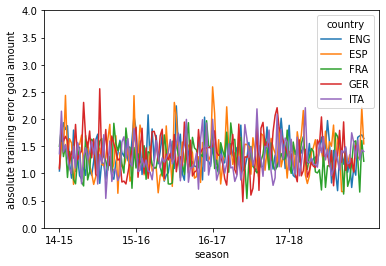

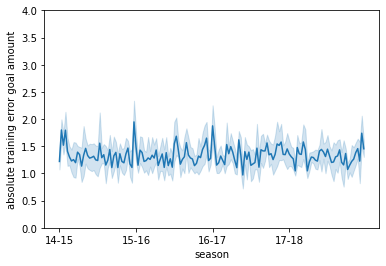

In [16]:
training_error_df = pd.read_csv('data/training_error.csv', sep=';')
sns.lineplot(data=training_error_df,
             x="season_matchnumber", y="abs_error_ga", hue="country")
plt.xticks(["14_1", "15_1", "16_1", "17_1"], [
           "14-15", "15-16", "16-17", "17-18"])
plt.ylim(0, 4)
plt.xlabel("season")
plt.ylabel("absolute training error goal amount")
plt.show()
sns.lineplot(data=training_error_df, x="season_matchnumber",
             y="abs_error_ga")
plt.xticks(["14_1", "15_1", "16_1", "17_1"], [
           "14-15", "15-16", "16-17", "17-18"])
plt.ylim(0, 4)
plt.xlabel("season")
plt.ylabel("absolute training error goal amount")
plt.show()


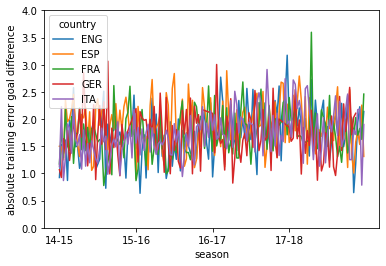

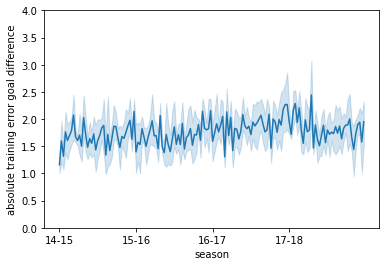

In [17]:
sns.lineplot(data=training_error_df, x="season_matchnumber",
             y="abs_error_gd", hue="country")
plt.xticks(["14_1", "15_1", "16_1", "17_1"], [
           "14-15", "15-16", "16-17", "17-18"])
plt.ylim(0, 4)
plt.xlabel("season")
plt.ylabel("absolute training error goal difference")
plt.show()
sns.lineplot(data=training_error_df, x="season_matchnumber",
             y="abs_error_gd")
plt.xticks(["14_1", "15_1", "16_1", "17_1"], [
           "14-15", "15-16", "16-17", "17-18"])
plt.ylim(0, 4)
plt.xlabel("season")
plt.ylabel("absolute training error goal difference")
plt.show()
